# Synthetic movement: a sub-wavelength shift from the cross-spectrum phase
A single PEC point scatterer in a homogeneous 10 m × 10 m medium ($\varepsilon_r = 5$, $\sigma = 10^{-5}$ S/m) moves **right and up** by a sub-wavelength amount between a baseline and a monitor zero-offset B-scan (gprMax, 2-D). Both B-scans are tapered in time and Kirchhoff-migrated, and the displacement is estimated with the cross-spectrum phase WLS method of Figure 1 in `Geophysical_Letter.ipynb`:
- $XS = \mathrm{FFT2}(b)\cdot\mathrm{FFT2}(m)^*$ of the Tukey-tapered migrated images, in a $\pm 2.5\lambda$ window around the scatterer;
- WLS fit of the phase plane $\arg XS = k_z\Delta z + k_x\Delta x + c$ over the bins with $|XS| > 0.10 \max|XS|$, weighted by $|XS|$.

Run with the `gprMax` kernel. Each of the three B-scans (background, baseline, monitor; 401 traces) takes ~25 min on the CPU; the gprMax outputs are kept in `New_Figures/synthetic_movement/` and a B-scan is only re-simulated when its input file changes.

In [1]:
import sys
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import numpy as np
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import hilbert
from gprMax.gprMax import api
from tools.outputfiles_merge import merge_files
from tools.plot_Bscan import get_output_data

# Repository root = the folder holding TimeLapse_Notebooks/ (works from New_Figures/ or the root)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'TimeLapse_Notebooks').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'TimeLapse_Notebooks'))
from helper_functions.KirchhoffPylopsZeroOffset import Kirchhoff
from helper_functions.migration import wls_phase_plane_fit

SIM_DIR = REPO_ROOT / 'New_Figures' / 'synthetic_movement'   # gprMax input/output files
OUT_DIR = REPO_ROOT / 'New_Figures' / 'figures'                # saved figures
OUT_DIR.mkdir(parents=True, exist_ok=True)

# One figure style for every panel (seaborn 'paper' context x FIG_SCALE)
FIG_SCALE = 1.4        # enlarges the figures; fonts, lines and markers scale with it
sns.set_theme(style='ticks', context='paper', font_scale=FIG_SCALE,
              rc={'lines.linewidth': FIG_SCALE, 'image.interpolation': 'nearest'})


def edge_extent(ax_h, ax_v):
    """imshow extent whose pixel edges (not centres) bracket the sample axes."""
    hh, hv = 0.5 * (ax_h[1] - ax_h[0]), 0.5 * (ax_v[1] - ax_v[0])
    return [ax_h[0] - hh, ax_h[-1] + hh, ax_v[0] - hv, ax_v[-1] + hv]

## Parameters
The centre frequency is 100 MHz (as in the field data), so $\lambda = v/f_c = 1.34$ m. The shift is rounded to the 2 cm FDTD grid, so the monitor scatterer is an exact translation of the baseline one.

In [2]:
# Medium and source wavelet
EPS_R = 5.0                          # relative permittivity
SIGMA = 1e-5                         # conductivity [S/m]
F_C = 0.1                            # Ricker centre frequency [GHz]
V = 0.299792458 / np.sqrt(EPS_R)     # wave speed [m/ns]
LAM = V / F_C                        # wavelength [m]
KZ_C = 2 * np.pi / LAM               # central wavenumber [rad/m]
T0 = np.sqrt(2) / F_C                # peak delay of the gprMax Ricker [ns]

# Model: 10 x 10 m, 2-D (one cell thick); gprMax y points up
DOMAIN = 10.0                        # domain side [m]
DX = 0.02                            # FDTD cell [m]
TIME_WINDOW = 130e-9                 # [s], covers the echo at the outermost traces
R_SCAT = LAM / 40                    # point scatterer: PEC cylinder of radius lambda/40
X_BASE, Y_BASE = 5.0, 5.0            # baseline scatterer position [m]

# Monitor: the scatterer moves right and up by a sub-wavelength amount (snapped to the grid)
SHIFT_RIGHT_LAM, SHIFT_UP_LAM = 1 / 30, 1 / 30
DX_TRUE = np.round(SHIFT_RIGHT_LAM * LAM / DX) * DX    # lateral shift [m], + = right
DZ_TRUE = -np.round(SHIFT_UP_LAM * LAM / DX) * DX      # depth shift [m], + = deeper

# Survey: Tx-Rx pairs stepped along the antenna line; traces sit at the Tx-Rx midpoints
Y_ANT = 9.5                          # antenna line height [m]; depth z is measured down from it
OFFSET = 0.2                         # Tx-Rx offset [m]
TRACE_STEP = 0.02                    # [m] = one FDTD cell
X_TRACES = np.arange(1.0, 9.0 + TRACE_STEP / 2, TRACE_STEP)
N_TRACES = len(X_TRACES)

# Time-decay taper exp(-t / tau) on the B-scans, tau = T_APEX / TAPER_STRENGTH: relative to the
# hyperbola apex, the flank recorded at angle theta from the scatterer gets the weight
# exp(-TAPER_STRENGTH * (1/cos(theta) - 1)). 0 = no taper; the thesis/Letter studies use 8.
TAPER_STRENGTH = 4.0
T_APEX = 2 * (Y_ANT - Y_BASE) / V    # two-way time of the baseline hyperbola apex [ns]
EDGE_DEG = np.degrees(np.arctan(max(X_BASE - X_TRACES[0], X_TRACES[-1] - X_BASE)
                                / (Y_ANT - Y_BASE)))   # widest angle the survey records

# Migrated image grid: Kirchhoff evaluates the image at any point, so its sampling is independent
# of the traces (finer = smoother images, but memory grows with image points x traces)
DX_IMG, DZ_IMG = 0.04, 0.02          # [m]
X_IMG = np.arange(X_TRACES[0], X_TRACES[-1] + DX_IMG / 2, DX_IMG)
Z_IMG = np.arange(0, 9.0, DZ_IMG)    # depth below the antenna line [m]

# Cross-spectrum phase WLS (as Figure 1 of Geophysical_Letter.ipynb)
CROP_HW_LAM = 2.5                    # half-width of the square analysis window [lambda]
AMP_THR = 0.10                       # fit only the bins with |XS| > AMP_THR * max|XS|
PAD_FAC = 4                          # FFT zero-padding: finer k sampling, same estimate

print(f'lambda = {LAM:.3f} m, FDTD cell = lambda/{LAM / DX:.0f}, '
      f'scatterer depth = {(Y_ANT - Y_BASE) / LAM:.2f} lambda, {N_TRACES} traces\n'
      f'shift: dx = {DX_TRUE * 1e3:+.0f} mm ({DX_TRUE / LAM:+.3f} lambda), '
      f'dz = {DZ_TRUE * 1e3:+.0f} mm ({DZ_TRUE / LAM:+.3f} lambda)\n'
      f'taper: weight at 30 deg = {np.exp(-TAPER_STRENGTH * (1 / np.cos(np.radians(30)) - 1)):.2f}, '
      f'at the survey edge ({EDGE_DEG:.0f} deg) = '
      f'{np.exp(-TAPER_STRENGTH * (1 / np.cos(np.radians(EDGE_DEG)) - 1)):.2f}')

lambda = 1.341 m, FDTD cell = lambda/67, scatterer depth = 3.36 lambda, 401 traces
shift: dx = +40 mm (+0.030 lambda), dz = -40 mm (-0.030 lambda)
taper: weight at 30 deg = 0.54, at the survey edge (42 deg) = 0.26

## gprMax input files
One input file per B-scan: the medium fills the whole domain, the point scatterer is a PEC cylinder (as in the thesis models), and the Tx–Rx pair steps along the antenna line with `#src_steps` / `#rx_steps` (one model run per trace). The background model has no scatterer; it is only used to remove the direct wave.

In [3]:
def write_input(name, scatterer=None):
    """Write the gprMax input file of one B-scan with the PEC point scatterer at
    scatterer = (x, y) [m] (None: background model). The file is only rewritten when its
    content changes, so run_bscan() re-simulates only what changed."""
    cylinder = '' if scatterer is None else (
        '#cylinder: {0:g} {1:g} 0 {0:g} {1:g} {2:g} {3:g} pec'.format(*scatterer, DX, R_SCAT))
    text = f"""#title: Synthetic movement - {name}
#domain: {DOMAIN:g} {DOMAIN:g} {DX:g}
#dx_dy_dz: {DX:g} {DX:g} {DX:g}
#time_window: {TIME_WINDOW:g}
#pml_cells: 10 10 0 10 10 0

#material: {EPS_R:g} {SIGMA:g} 1 0 medium
#box: 0 0 0 {DOMAIN:g} {DOMAIN:g} {DX:g} medium
{cylinder}

#waveform: ricker 1 {F_C * 1e9:g} pulse
#hertzian_dipole: z {X_TRACES[0] - OFFSET / 2:g} {Y_ANT:g} 0 pulse
#rx: {X_TRACES[0] + OFFSET / 2:g} {Y_ANT:g} 0
#src_steps: {TRACE_STEP:g} 0 0
#rx_steps: {TRACE_STEP:g} 0 0
"""
    path = SIM_DIR / f'{name}.in'
    if not path.exists() or path.read_text() != text:
        path.write_text(text)
    return path


SIM_DIR.mkdir(parents=True, exist_ok=True)
IN_FILES = {'background': write_input('background'),
            'baseline': write_input('baseline', (X_BASE, Y_BASE)),
            'monitor': write_input('monitor', (X_BASE + DX_TRUE, Y_BASE - DZ_TRUE))}
print(IN_FILES['monitor'].read_text())

#title: Synthetic movement - monitor
#domain: 10 10 0.02
#dx_dy_dz: 0.02 0.02 0.02
#time_window: 1.3e-07
#pml_cells: 10 10 0 10 10 0

#material: 5 1e-05 1 0 medium
#box: 0 0 0 10 10 0.02 medium
#cylinder: 5.04 5.04 0 5.04 5.04 0.02 0.0335178 pec

#waveform: ricker 1 1e+08 pulse
#hertzian_dipole: z 0.9 9.5 0 pulse
#rx: 1.1 9.5 0
#src_steps: 0.02 0 0
#rx_steps: 0.02 0 0


## Simulation and B-scan preprocessing
As in `TimeLapse_Playground.ipynb`: the background B-scan is subtracted to remove the direct wave, the Ricker peak delay $t_0 = \sqrt{2}/f_c$ is removed, and a time-decay taper $w(t) = e^{-t/\tau}$ is applied before migration.

**Why the taper.** The survey ends abruptly, at about $\pm 42°$ as seen from the scatterer. Without a taper, that hard edge leaves energy at all wavenumbers in the migrated images. That energy does not move rigidly with the scatterer, so it biases the estimate (mostly $\Delta x$). Along a hyperbola with apex time $t_{apex}$, the flank recorded at angle $\theta$ arrives at $t_{apex}/\cos\theta$, so relative to the apex the taper weights it by $\exp[-S\,(1/\cos\theta - 1)]$, with $S = t_{apex}/\tau$ = `TAPER_STRENGTH`. The time taper is therefore a smooth taper in angle that follows the scatterer.

In [4]:
def run_bscan(infile):
    """Simulate the B-scan (one gprMax run per trace) unless its merged output is newer than
    the input file; return Ez (n_t, n_traces) and the time step [ns]."""
    merged = infile.with_name(infile.stem + '_merged.out')
    if not merged.exists() or merged.stat().st_mtime < infile.stat().st_mtime:
        with redirect_stdout(StringIO()):      # keep gprMax's per-trace log out of the notebook
            api(str(infile), n=N_TRACES)
        merge_files(str(infile.with_suffix('')), removefiles=True)
    data, dt = get_output_data(str(merged), 1, 'Ez')
    return data, dt * 1e9


RAW = {name: run_bscan(path) for name, path in IN_FILES.items()}
dt_ns = RAW['baseline'][1]
i0 = round(T0 / dt_ns)                                   # t = 0 at the Ricker peak
BSCAN = {name: (RAW[name][0] - RAW['background'][0])[i0:] for name in ('baseline', 'monitor')}
t = np.arange(BSCAN['baseline'].shape[0]) * dt_ns

TAPER = np.exp(-TAPER_STRENGTH * t / T_APEX)             # w(t) = exp(-t / tau)
TAPERED = {name: b * TAPER[:, None] for name, b in BSCAN.items()}

### B-scans
Top row: the recorded B-scans after background subtraction and $t_0$ correction, and their difference. Bottom row: the taper weight relative to the apex, with the arrival times of the apex, the 30° flank and the survey edge (dotted), and the tapered B-scans that go into the migration. Each panel has its own symmetric colour scale. The markers show the true baseline (○) and monitor (×) scatterer positions in B-scan coordinates, i.e. at the hyperbola apex $(x_s,\ 2d/v)$; the insets in (a) and (b) zoom on the apex, because the sub-wavelength shift is smaller than a marker at full scale (the 0.1 m trace spacing makes the inset blocky).

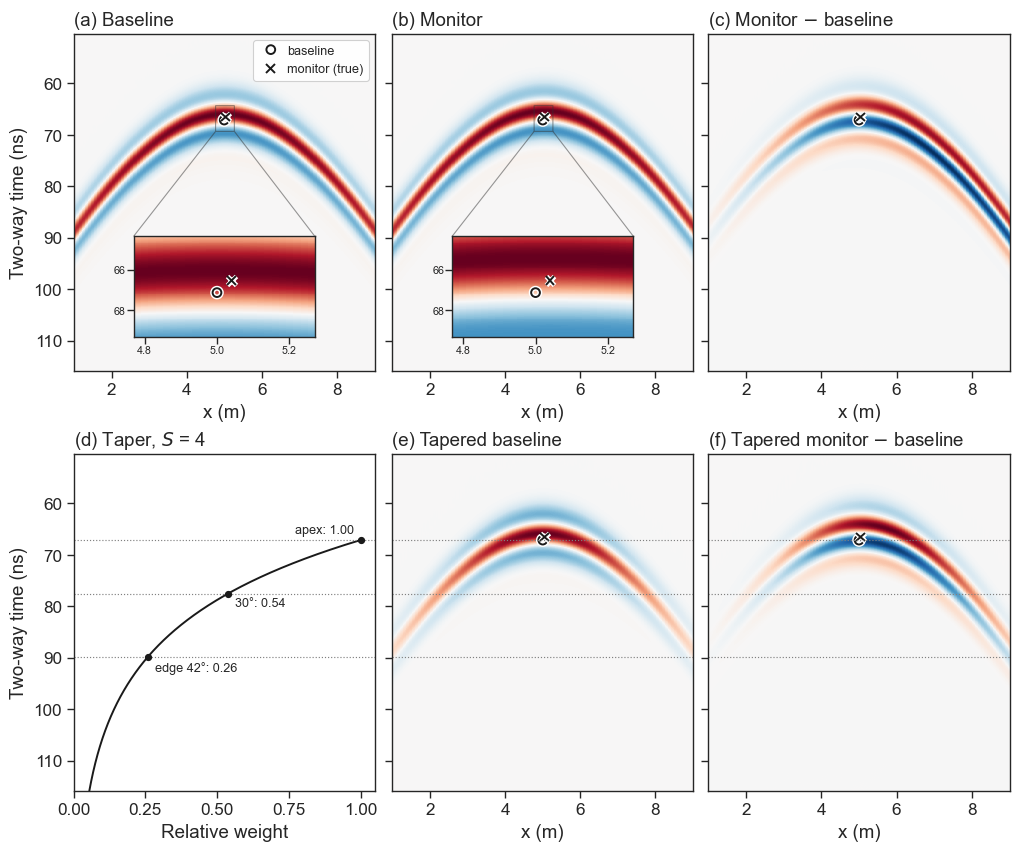

In [5]:
# True scatterer positions in B-scan coordinates: the hyperbola apex (x_s, 2 d / v)
APEX = {'baseline': (X_BASE, T_APEX),
        'monitor': (X_BASE + DX_TRUE, 2 * (Y_ANT - Y_BASE + DZ_TRUE) / V)}
MK = dict(ms=4.5 * FIG_SCALE, mew=FIG_SCALE, ls='none',      # white halo: visible on any colour
          path_effects=[pe.withStroke(linewidth=2.5 * FIG_SCALE, foreground='w')])
INSET_HW = (0.25, 2.5)   # half-width of the apex zoom inset: (x [m], t [ns])


def bscan_panel(ax, data, title, cmap='gray', inset=False):
    """B-scan with time increasing downwards, a symmetric colour scale and markers at the
    true baseline and monitor scatterer positions; inset=True adds a zoom on the apex in
    the empty lower part of the panel."""
    ext = edge_extent(X_TRACES, t)
    vmax = np.abs(data).max()
    axes = [ax, ax.inset_axes([0.2, 0.1, 0.6, 0.3])] if inset else [ax]
    for a in axes:
        a.imshow(data, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper', aspect='auto',
                 cmap=cmap, vmin=-vmax, vmax=vmax)
        a.plot(*APEX['baseline'], marker='o', mfc='none', mec='k', label='baseline', **MK)
        a.plot(*APEX['monitor'], marker='x', mec='k', label='monitor (true)', **MK)
    if inset:
        axin = axes[1]
        x_c, t_c = np.mean([APEX['baseline'], APEX['monitor']], axis=0)
        axin.set_xlim(x_c - INSET_HW[0], x_c + INSET_HW[0])
        axin.set_ylim(t_c + INSET_HW[1], t_c - INSET_HW[1])
        axin.tick_params(labelsize=5.5 * FIG_SCALE, pad=1)
        for axis in (axin.xaxis, axin.yaxis):
            axis.set_major_locator(plt.MaxNLocator(3))
        ax.indicate_inset_zoom(axin, edgecolor='0.2')
    ax.set_title(title, loc='left')


fig, axs = plt.subplots(2, 3, figsize=(7.2 * FIG_SCALE, 6.0 * FIG_SCALE), sharey=True,
                        layout='constrained')
bscan_panel(axs[0, 0], BSCAN['baseline'], '(a) Baseline', cmap='RdBu_r', inset=True)
bscan_panel(axs[0, 1], BSCAN['monitor'], '(b) Monitor', cmap='RdBu_r', inset=True)
bscan_panel(axs[0, 2], BSCAN['monitor'] - BSCAN['baseline'], '(c) Monitor $-$ baseline', 'RdBu_r')
bscan_panel(axs[1, 1], TAPERED['baseline'], '(e) Tapered baseline', cmap='RdBu_r')
bscan_panel(axs[1, 2], TAPERED['monitor'] - TAPERED['baseline'],
            '(f) Tapered monitor $-$ baseline', 'RdBu_r')
axs[0, 0].legend(loc='upper right', fontsize=6.5 * FIG_SCALE, handletextpad=0.3, borderpad=0.4,
                 framealpha=0.9)

# (d) Taper weight relative to the hyperbola apex (no scatterer energy arrives before it)
ax = axs[1, 0]
after = t >= T_APEX
ax.plot(np.exp(-TAPER_STRENGTH * (t[after] / T_APEX - 1)), t[after], color='k')
for ang, lbl in [(0, 'apex'), (30, '30°'), (EDGE_DEG, f'edge {EDGE_DEG:.0f}°')]:
    t_ang = T_APEX / np.cos(np.radians(ang))
    w_ang = np.exp(-TAPER_STRENGTH * (1 / np.cos(np.radians(ang)) - 1))
    for a in axs[1]:
        a.axhline(t_ang, color='0.5', ls=':', lw=0.6 * FIG_SCALE)
    ax.plot(w_ang, t_ang, 'o', color='k', ms=3 * FIG_SCALE)
    # label on the side away from the curve: upper-left of high weights, lower-right of low ones
    left = w_ang > 0.6
    ax.annotate(f'{lbl}: {w_ang:.2f}', (w_ang, t_ang), xytext=(-5, 3) if left else (5, -3),
                textcoords='offset points', ha='right' if left else 'left',
                va='bottom' if left else 'top', fontsize=6.5 * FIG_SCALE)
ax.set_xlim(0, 1.05)
ax.set_xlabel('Relative weight')
ax.set_title(rf'(d) Taper, $S$ = {TAPER_STRENGTH:g}', loc='left')

axs[0, 0].set_ylim(t[-1], 0.75 * T_APEX)                 # shared; nothing arrives before the apex
for a in axs[:, 0]:
    a.set_ylabel('Two-way time (ns)')
for a in [*axs[0], *axs[1, 1:]]:
    a.set_xlabel('x (m)')
fig.savefig(OUT_DIR / 'synthetic_movement_bscans.png', dpi=300, bbox_inches='tight')
plt.show()

## Kirchhoff migration
The migration is the adjoint of the thesis' zero-offset Kirchhoff operator (the one behind `PylopsKirchoffMigration`). It is built here with a $\pm 1.5$-period Ricker, because the helper's default 6-period wavelet is longer than these 100 MHz traces. The image is evaluated on its own `DX_IMG` × `DZ_IMG` grid rather than at the trace positions.

In [6]:
# Zero-offset Kirchhoff operator (Tx = Rx at depth 0) with a +-1.5-period Ricker wavelet
n_w = int(1.5 / F_C / dt_ns)
t_w = np.arange(-n_w, n_w + 1) * dt_ns
wav = (1 - 2 * (np.pi * F_C * t_w) ** 2) * np.exp(-(np.pi * F_C * t_w) ** 2)
xz = np.vstack([X_TRACES, np.zeros(N_TRACES)])
K = Kirchhoff(Z_IMG, X_IMG, t, xz, xz, V, wav, n_w)
IMG = {name: (K.H @ b.T.ravel()).reshape(len(X_IMG), len(Z_IMG)).T    # (n_z, n_x)
       for name, b in TAPERED.items()}
del K                                                    # frees its traveltime tables

### Migrated images
The migrated baseline and monitor images and their difference, each with its own symmetric colour scale. The markers show the true baseline (○) and monitor (×) scatterer positions $(x_s, d)$. The insets zoom on the scatterer; their image is the same Kirchhoff migration evaluated directly on a fine 5 mm grid, not an interpolation of the coarser main image.

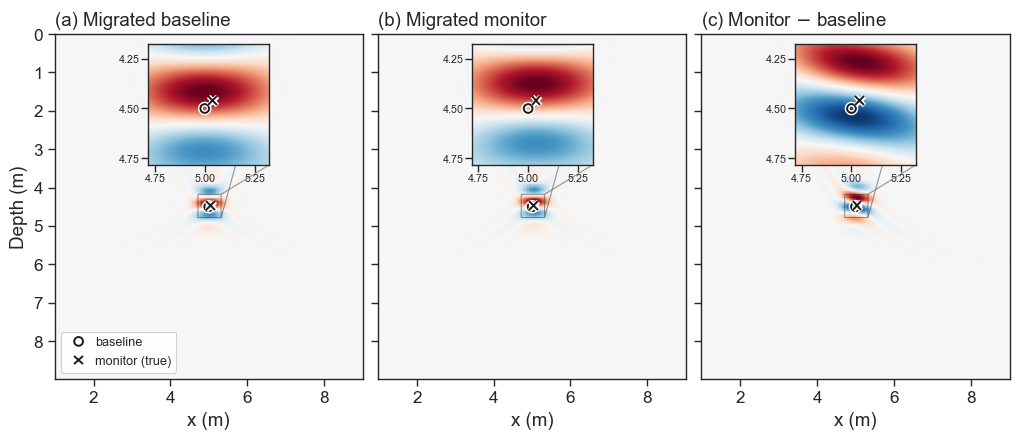

In [7]:
# True scatterer positions in image coordinates (x, depth below the antenna line)
POS = {'baseline': (X_BASE, Y_ANT - Y_BASE),
       'monitor': (X_BASE + DX_TRUE, Y_ANT - Y_BASE + DZ_TRUE)}

# Zoom images: the Kirchhoff migration evaluated on a fine grid around the scatterer
ZOOM_HW, ZOOM_STEP = 0.3, 0.005                          # half-width and grid step [m]
x_c, z_c = np.mean([POS['baseline'], POS['monitor']], axis=0)
X_ZOOM = x_c + np.arange(-ZOOM_HW, ZOOM_HW + ZOOM_STEP / 2, ZOOM_STEP)
Z_ZOOM = z_c + np.arange(-ZOOM_HW, ZOOM_HW + ZOOM_STEP / 2, ZOOM_STEP)
K_zoom = Kirchhoff(Z_ZOOM, X_ZOOM, t, xz, xz, V, wav, n_w)
ZOOM = {name: (K_zoom.H @ b.T.ravel()).reshape(len(X_ZOOM), len(Z_ZOOM)).T
        for name, b in TAPERED.items()}
del K_zoom


def image_panel(ax, img, zoom, title):
    """Migrated image (depth down, equal axes, symmetric colours) with markers at the true
    positions and a zoom inset (fine-grid image) in the upper part of the panel."""
    vmax = np.abs(img).max()
    axin = ax.inset_axes([0.25, 0.62, 0.5, 0.35])
    for a, data, x, z in [(ax, img, X_IMG, Z_IMG), (axin, zoom, X_ZOOM, Z_ZOOM)]:
        ext = edge_extent(x, z)
        a.imshow(data, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper', cmap='RdBu_r',
                 vmin=-vmax, vmax=vmax)
        a.plot(*POS['baseline'], marker='o', mfc='none', mec='k', label='baseline', **MK)
        a.plot(*POS['monitor'], marker='x', mec='k', label='monitor (true)', **MK)
    axin.tick_params(labelsize=5.5 * FIG_SCALE, pad=1)
    for axis in (axin.xaxis, axin.yaxis):
        axis.set_major_locator(plt.MaxNLocator(3))
    ax.indicate_inset_zoom(axin, edgecolor='0.2')
    ax.set_title(title, loc='left')
    ax.set_xlabel('x (m)')


fig, axs = plt.subplots(1, 3, figsize=(7.2 * FIG_SCALE, 3.4 * FIG_SCALE), sharey=True,
                        layout='constrained')
image_panel(axs[0], IMG['baseline'], ZOOM['baseline'], '(a) Migrated baseline')
image_panel(axs[1], IMG['monitor'], ZOOM['monitor'], '(b) Migrated monitor')
image_panel(axs[2], IMG['monitor'] - IMG['baseline'], ZOOM['monitor'] - ZOOM['baseline'],
            '(c) Monitor $-$ baseline')
axs[0].set_ylabel('Depth (m)')
axs[0].legend(loc='lower left', fontsize=6.5 * FIG_SCALE, handletextpad=0.3, borderpad=0.4,
              framealpha=0.9)
fig.savefig(OUT_DIR / 'synthetic_movement_migrated.png', dpi=300, bbox_inches='tight')
plt.show()

## Cross-spectrum phase WLS
The analysis window is a $\pm 2.5\lambda$ square centred on the baseline scatterer $(x_0, z_0)$, taken as the peak of the baseline envelope. The cross-spectrum and the fit both come from `helper_functions.migration.wls_phase_plane_fit`: Tukey taper ($\alpha = 0.15$), WLS weights $|XS|$, and the energy-threshold mask of `Geophysical_Letter.ipynb`. Unlike the Letter, the FFT is zero-padded `PAD_FAC` times. That only samples the spectrum more finely (smoother panel b); the estimate is the same as without padding.

In [8]:
# Analysis window around the baseline scatterer (x0, z0) = peak of the baseline envelope
env = np.abs(hilbert(IMG['baseline'], axis=0))
iz0, ix0 = np.unravel_index(np.argmax(env), env.shape)
hz, hx = round(CROP_HW_LAM * LAM / DZ_IMG), round(CROP_HW_LAM * LAM / DX_IMG)
win = np.s_[iz0 - hz:iz0 + hz + 1, ix0 - hx:ix0 + hx + 1]
base, mon = IMG['baseline'][win], IMG['monitor'][win]
x_rel = (X_IMG[win[1]] - X_IMG[ix0]) / LAM          # axes relative to (x0, z0) [lambda]
z_rel = (Z_IMG[win[0]] - Z_IMG[iz0]) / LAM

# 1st call: the (zero-padded) cross-spectrum XS = FFT2(b) FFT2(m)* only; 2nd call: the WLS
# phase-plane fit over the bins above the energy threshold (DC excluded)
xs_kw = dict(taper='tukey', tukey_alpha=0.15, pad_fac=PAD_FAC)
diag = wls_phase_plane_fit(base, mon, DZ_IMG, DX_IMG, KZ_C, return_diagnostics=True, **xs_kw)[4]
XS, kz_ax, kx_ax = diag['w'] * np.exp(1j * diag['phi']), diag['kz_ax'], diag['kx_ax']
fit_mask = (diag['w'] > AMP_THR * diag['w'].max()) & ((np.abs(diag['KZ']) + np.abs(diag['KX'])) > 0)
dz_est, dx_est, phi0, _ = wls_phase_plane_fit(base, mon, DZ_IMG, DX_IMG, KZ_C, mask=fit_mask,
                                              **xs_kw)

print(f'dx: true {DX_TRUE * 1e3:+.1f} mm, est. {dx_est * 1e3:+.2f} mm\n'
      f'dz: true {DZ_TRUE * 1e3:+.1f} mm, est. {dz_est * 1e3:+.2f} mm   (+ = right / deeper)')

dx: true +40.0 mm, est. +40.41 mm
dz: true -40.0 mm, est. -40.00 mm   (+ = right / deeper)

## Figure
- **(a)** Difference image (monitor $-$ baseline) / max|baseline|, on axes relative to the baseline scatterer in units of $\lambda$; markers show the baseline scatterer and the true monitor position.
- **(b)** $\arg(XS)$ with $k$ normalised by $k_{z,c}$; opaque and outlined where $|XS| > 0.10\max|XS|$, i.e. the bins the WLS fit uses. The marginal strips show their raw phase against $k_x$ (top) and $k_z$ (right): the slope of each cloud is $\Delta x$ and $\Delta z$. Because of the Hermitian symmetry $\arg XS(-\mathbf{k}) = -\arg XS(\mathbf{k})$ each strip has two blobs, one per lobe. The blue lines are the fitted plane $\Phi = k_x\Delta x + k_z\Delta z + \phi_0$ evaluated at each lobe's $|XS|$-weighted mean $k_z$ (top) or $k_x$ (right). Both lines in a strip share the fitted slope, and their offset $\pm\bar{k}_z\Delta z$ (top) or $\pm\bar{k}_x\Delta x$ (right) is what separates the blobs.

Saved to `New_Figures/figures/synthetic_movement_kirchhoff.png` (dpi = 300).

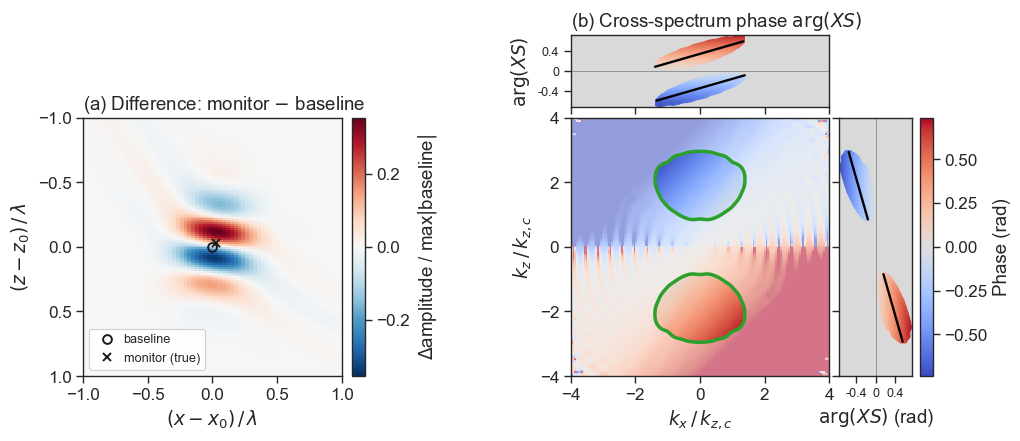

In [9]:
PHASE_CMAP = 'coolwarm'  # diverging phase map: blue (-) -> grey (0) -> red (+)
ALPHA_LOW = 0.55       # alpha of the below-threshold bins
K_LIM = 4.0            # half-width of the plotted k-window [k_zc]
VIEW_HW_LAM = 1.0      # half-width of the panel (a) zoom [lambda]
MARG_FRAC = 0.28       # thickness of the marginal strips [fraction of panel (b)]

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2 * FIG_SCALE, 3.8 * FIG_SCALE),
                                 layout='constrained')
fig.get_layout_engine().set(wspace=0.14)    # room for panel (a)'s colour-bar label
fs = 6.5 * FIG_SCALE                         # small-print font size

# (a) Difference image, depth increasing downwards
diff = (mon - base) / np.abs(base).max()
ext = edge_extent(x_rel, z_rel)
vmax = np.abs(diff).max()
im_a = ax_a.imshow(diff, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper',
                   cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax_a.set_xlim(-VIEW_HW_LAM, VIEW_HW_LAM)
ax_a.set_ylim(VIEW_HW_LAM, -VIEW_HW_LAM)
ax_a.set_xlabel(r'$(x - x_0)\,/\,\lambda$')
ax_a.set_ylabel(r'$(z - z_0)\,/\,\lambda$')
mk = dict(ms=4.5 * FIG_SCALE, mew=FIG_SCALE, ls='none')
ax_a.plot(0, 0, marker='o', mfc='none', mec='k', label='baseline', **mk)
ax_a.plot(DX_TRUE / LAM, DZ_TRUE / LAM, marker='x', mec='k', label='monitor (true)', **mk)
ax_a.legend(loc='lower left', fontsize=fs, handletextpad=0.3, borderpad=0.4, framealpha=0.9)
ax_a.set_title('(a) Difference: monitor $-$ baseline', loc='left')
fig.colorbar(im_a, cax=ax_a.inset_axes([1.04, 0, 0.05, 1]),
             label=r'$\Delta$amplitude / max$|$baseline$|$')
txt = '\n'.join(rf'$\Delta {c} = {true / LAM:+.3f}\,\lambda = {true * 1e3:+.0f}$ mm, '
                rf'est. ${est * 1e3:+.1f}$ mm'
                for c, true, est in [('x', DX_TRUE, dx_est), ('z', DZ_TRUE, dz_est)])
# ax_a.text(0.03, 0.97, txt, transform=ax_a.transAxes, fontsize=fs, va='top', ha='left',
#           bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='0.7', lw=0.5 * FIG_SCALE))

# (b) Cross-spectrum phase (fftshifted, k / k_zc), k_z increasing upwards
phase = np.fft.fftshift(np.angle(XS))
amp = np.fft.fftshift(np.abs(XS)) / np.abs(XS).max()
kz_n, kx_n = np.fft.fftshift(kz_ax) / KZ_C, np.fft.fftshift(kx_ax) / KZ_C
sel = amp > AMP_THR                          # the bins the WLS fit uses
ph_lim = 1.05 * np.abs(phase[sel]).max()     # colour range spans the phases in the lobes
im_b = ax_b.imshow(phase, extent=edge_extent(kx_n, kz_n), origin='lower', cmap=PHASE_CMAP,
                   vmin=-ph_lim, vmax=ph_lim, alpha=np.where(sel, 1.0, ALPHA_LOW))
ax_b.contour(kx_n, kz_n, amp, levels=[AMP_THR], colors='tab:green', linewidths=1.8 * FIG_SCALE)
ax_b.set_xlim(-K_LIM, K_LIM)
ax_b.set_ylim(-K_LIM, K_LIM)
ax_b.set_xlabel(r'$k_x \,/\, k_{z,c}$')
ax_b.set_ylabel(r'$k_z \,/\, k_{z,c}$')

# Marginal strips: raw arg(XS) of the fit bins against k_x (top) and k_z (right)
KZ_n, KX_n = np.meshgrid(kz_n, kx_n, indexing='ij')
ax_top = ax_b.inset_axes([0, 1.04, 1, MARG_FRAC], sharex=ax_b)
ax_rgt = ax_b.inset_axes([1.04, 0, MARG_FRAC, 1], sharey=ax_b)
sc_kw = dict(c=phase[sel], cmap=PHASE_CMAP, vmin=-ph_lim, vmax=ph_lim, s=3 * FIG_SCALE ** 2,
             linewidths=0, rasterized=True)
ax_top.scatter(KX_n[sel], phase[sel], **sc_kw)
ax_rgt.scatter(phase[sel], KZ_n[sel], **sc_kw)

# Fitted plane phi = kx dx + kz dz + phi0 in the strips, one line per Hermitian lobe: the plane
# at the lobe's |XS|-weighted mean k_z (top) or k_x (right), drawn over the lobe's extent. Both
# lines share the fitted slope (dx on top, dz on the right); the +-mean-k offsets separate the blobs.
fit_kw = dict(color='black', lw=1.2 * FIG_SCALE)
for lobe in (KZ_n > 0, KZ_n < 0):
    m_ = sel & lobe
    kz_mean, kx_mean = (np.average(k[m_], weights=amp[m_]) for k in (KZ_n, KX_n))
    kx_line = np.array([KX_n[m_].min(), KX_n[m_].max()])
    kz_line = np.array([KZ_n[m_].min(), KZ_n[m_].max()])
    ax_top.plot(kx_line, KZ_C * (kx_line * dx_est + kz_mean * dz_est) + phi0, **fit_kw)
    ax_rgt.plot(KZ_C * (kz_line * dz_est + kx_mean * dx_est) + phi0, kz_line, **fit_kw)
# ax_top.legend(ax_top.lines[-1:], ['fitted plane'], loc='upper left', fontsize=5.5 * FIG_SCALE,
#               handlelength=1.2, borderpad=0.3, framealpha=0.9)
for ax in (ax_top, ax_rgt):
    ax.set_facecolor('0.85')                 # grey, so near-0 (white) phases stay visible
ax_top.axhline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
ax_rgt.axvline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
tk = float(f'{0.6 * ph_lim:.1g}')            # strip ticks well inside +-ph_lim
ticks, tick_lbls = [-tk, 0, tk], [f'{-tk:g}', '0', f'{tk:g}']
ax_top.set_ylim(-ph_lim, ph_lim)
ax_top.set_yticks(ticks, tick_lbls, fontsize=fs)
ax_top.set_ylabel(r'$\arg(XS)$')
ax_top.tick_params(labelbottom=False)
ax_rgt.set_xlim(-ph_lim, ph_lim)
ax_rgt.set_xticks(ticks, tick_lbls, fontsize=fs)
ax_rgt.set_xlabel(r'$\arg(XS)$ (rad)')
ax_rgt.tick_params(labelleft=False)
ax_top.set_title(r'(b) Cross-spectrum phase $\arg(XS)$', loc='left')
cb_b = fig.colorbar(im_b, cax=ax_b.inset_axes([1.07 + MARG_FRAC, 0, 0.05, 1]),
                    label='Phase (rad)')
cb_b.solids.set_alpha(1.0)                   # colour bar shows the opaque colours

# Align panel (a) with the phase map itself (not the map + top strip)
ax_a.set_anchor('S')
ax_b.set_anchor('S')

fig.savefig(OUT_DIR / 'synthetic_movement_kirchhoff.png', dpi=300, bbox_inches='tight')
plt.show()

### Figure, version A: density strips
The same figure, but the marginal strips show the probability density of the fit bins instead of their raw phases: an $|XS|$-weighted 2-D histogram (the WLS weights) of $(k_x, \arg XS)$ (top) and $(k_z, \arg XS)$ (right), normalised to a joint density $p(k, \arg XS)$ over both lobes. Blue is the $k_z > 0$ lobe and red the $k_z < 0$ lobe; the opacity rises with the density, up to full opacity at each strip's peak. Because the phase is a plane, the width of each band is the spread of the other wavenumber term ($k_z\Delta z$ on top, $k_x\Delta x$ on the right) over the lobe, not noise: the density shows where the weight of the fit lies, which the raw points (all drawn equally) do not.

Saved to `New_Figures/figures/synthetic_movement_kirchhoff_density.png` (dpi = 300).

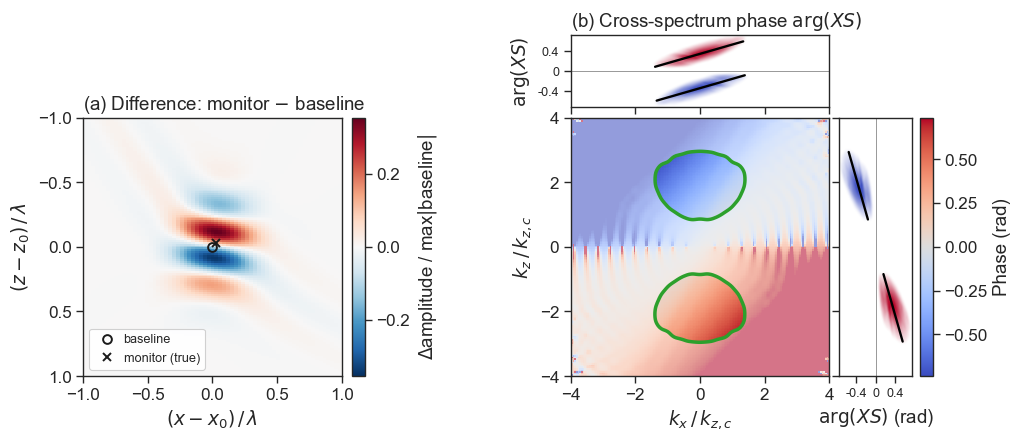

In [10]:
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

# Version A of the figure above: the marginal strips show the |XS|-weighted probability density
# of the fit bins instead of their raw phases. Reuses the arrays and settings of the cell above.
PH_BINS = 80           # phase bins of the strip densities
DENS_SMOOTH = 1.0      # Gaussian smoothing of the strip densities [bins]

ph_edges = np.linspace(-ph_lim, ph_lim, PH_BINS + 1)
ph_c = 0.5 * (ph_edges[1:] + ph_edges[:-1])
lobes = (KZ_n > 0, KZ_n < 0)
# One hue per lobe (the phase map's end colours: blue k_z > 0, red k_z < 0) with opacity rising
# from 0 to 1 with density, so low densities fade into the white strip background
lobe_cmaps = [LinearSegmentedColormap.from_list('lobe', [(*rgb, 0), (*rgb, 1)])
              for rgb in (plt.get_cmap(PHASE_CMAP)(v)[:3] for v in (0.0, 1.0))]


def strip_density(k, k_ax):
    """|XS|-weighted 2-D histogram of the fit bins in (arg XS, k), normalised to a joint
    probability density p(k, arg XS) over both lobes; one (n_phase, n_k) array per lobe."""
    dk = k_ax[1] - k_ax[0]
    k_edges = np.r_[k_ax - dk / 2, k_ax[-1] + dk / 2]
    hists = [gaussian_filter(np.histogram2d(phase[sel & lobe], k[sel & lobe],
                                            [ph_edges, k_edges], weights=amp[sel & lobe])[0],
                             DENS_SMOOTH)
             for lobe in lobes]
    norm = sum(h.sum() for h in hists) * (ph_edges[1] - ph_edges[0]) * dk
    return [h / norm for h in hists]


fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(7.2 * FIG_SCALE, 3.8 * FIG_SCALE),
                                 layout='constrained')
fig.get_layout_engine().set(wspace=0.14)    # room for panel (a)'s colour-bar label

# (a) Difference image, as in the figure above
ext = edge_extent(x_rel, z_rel)
vmax = np.abs(diff).max()
im_a = ax_a.imshow(diff, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper',
                   cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax_a.set_xlim(-VIEW_HW_LAM, VIEW_HW_LAM)
ax_a.set_ylim(VIEW_HW_LAM, -VIEW_HW_LAM)
ax_a.set_xlabel(r'$(x - x_0)\,/\,\lambda$')
ax_a.set_ylabel(r'$(z - z_0)\,/\,\lambda$')
ax_a.plot(0, 0, marker='o', mfc='none', mec='k', label='baseline', **mk)
ax_a.plot(DX_TRUE / LAM, DZ_TRUE / LAM, marker='x', mec='k', label='monitor (true)', **mk)
ax_a.legend(loc='lower left', fontsize=fs, handletextpad=0.3, borderpad=0.4, framealpha=0.9)
ax_a.set_title('(a) Difference: monitor $-$ baseline', loc='left')
fig.colorbar(im_a, cax=ax_a.inset_axes([1.04, 0, 0.05, 1]),
             label=r'$\Delta$amplitude / max$|$baseline$|$')

# (b) Cross-spectrum phase, as in the figure above
im_b = ax_b.imshow(phase, extent=edge_extent(kx_n, kz_n), origin='lower', cmap=PHASE_CMAP,
                   vmin=-ph_lim, vmax=ph_lim, alpha=np.where(sel, 1.0, ALPHA_LOW))
ax_b.contour(kx_n, kz_n, amp, levels=[AMP_THR], colors='tab:green', linewidths=1.8 * FIG_SCALE)
ax_b.set_xlim(-K_LIM, K_LIM)
ax_b.set_ylim(-K_LIM, K_LIM)
ax_b.set_xlabel(r'$k_x \,/\, k_{z,c}$')
ax_b.set_ylabel(r'$k_z \,/\, k_{z,c}$')

# Marginal strips: density of the fit bins against k_x (top) and k_z (right), one image per lobe
ax_top = ax_b.inset_axes([0, 1.04, 1, MARG_FRAC], sharex=ax_b)
ax_rgt = ax_b.inset_axes([1.04, 0, MARG_FRAC, 1], sharey=ax_b)
for ax, k, k_ax, top in [(ax_top, KX_n, kx_n, True), (ax_rgt, KZ_n, kz_n, False)]:
    dens = strip_density(k, k_ax)
    d_max = max(h.max() for h in dens)       # full opacity at the strip's peak density
    for h, cmap in zip(dens, lobe_cmaps):
        h, ext_s = (h, edge_extent(k_ax, ph_c)) if top else (h.T, edge_extent(ph_c, k_ax))
        ax.imshow(h, extent=ext_s, origin='lower', aspect='auto', interpolation='bilinear',
                  cmap=cmap, vmin=0, vmax=d_max)

# Fitted plane in the strips, one line per Hermitian lobe (as in the figure above)
for lobe in lobes:
    m_ = sel & lobe
    kz_mean, kx_mean = (np.average(k[m_], weights=amp[m_]) for k in (KZ_n, KX_n))
    kx_line = np.array([KX_n[m_].min(), KX_n[m_].max()])
    kz_line = np.array([KZ_n[m_].min(), KZ_n[m_].max()])
    ax_top.plot(kx_line, KZ_C * (kx_line * dx_est + kz_mean * dz_est) + phi0, **fit_kw)
    ax_rgt.plot(KZ_C * (kz_line * dz_est + kx_mean * dx_est) + phi0, kz_line, **fit_kw)
ax_top.axhline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
ax_rgt.axvline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
ax_top.set_ylim(-ph_lim, ph_lim)
ax_top.set_yticks(ticks, tick_lbls, fontsize=fs)
ax_top.set_ylabel(r'$\arg(XS)$')
ax_top.tick_params(labelbottom=False)
ax_rgt.set_xlim(-ph_lim, ph_lim)
ax_rgt.set_xticks(ticks, tick_lbls, fontsize=fs)
ax_rgt.set_xlabel(r'$\arg(XS)$ (rad)')
ax_rgt.tick_params(labelleft=False)
ax_top.set_title(r'(b) Cross-spectrum phase $\arg(XS)$', loc='left')
cb_b = fig.colorbar(im_b, cax=ax_b.inset_axes([1.07 + MARG_FRAC, 0, 0.05, 1]),
                    label='Phase (rad)')
cb_b.solids.set_alpha(1.0)                   # colour bar shows the opaque colours

# Align panel (a) with the phase map itself (not the map + top strip)
ax_a.set_anchor('S')
ax_b.set_anchor('S')

fig.savefig(OUT_DIR / 'synthetic_movement_kirchhoff_density.png', dpi=300, bbox_inches='tight')
plt.show()

### Figure: the method in one view
The steps of the method in one figure (layout of `New_Figures/figure_design.pdf`):
- **(a), (b)** The migrated images at T1 (baseline) and T2 (monitor) in a $\pm 0.7\lambda$ square (`T_HW_LAM`) around the baseline scatterer $(x_0, z_0)$. Both panels have the same axis limits and one shared symmetric colour scale, with small ticks every 0.5 m (`ZOOM_TICK`). The markers show the true T1 (○) and T2 (×) scatterer positions. The T2 image has moved 40 mm right and 40 mm up, about 2 % of the panel width (1 pixel laterally, 2 pixels vertically on the migration grid), so the shift can hardly be seen by eye. The migrated peaks lie ~80 mm above the true centres, equally in T1 and T2.
- **(c)** The amplitude difference T2 $-$ T1 over the whole 10 m × 10 m view (`OVERVIEW_LIM`, depth below the antenna line): the change is confined to the dashed box. Because the migration grid of the analysis stops at the survey ends ($x$ = 1–9 m), this panel is the same Kirchhoff migration evaluated on its own grid over the full view. Its depth ticks are on the right, where (d) hides the 4 and 6 m labels; the depth-axis label at the far left serves (a), (b) and (c). The scale bar is one wavelength.
- **(d)** Zoom on the dashed box, a $\pm 0.6\lambda$ square (`BOX_HW_LAM`), on the colour scale of (c), with the ticks of (a) and (b).
- **(e)** Cross-spectrum phase with the $|XS|$-weighted density strips, as in version A above, but on wavenumber axes in rad/m: the strips show the phase $\phi$ against $k_x$ (top) and $k_z$ (right). In the strips the hue marks the Hermitian lobe (blue: $k_z > 0$, red: $k_z < 0$; the end colours of the phase map) and the opacity the $|XS|$-weighted density, so the strip colours are not phase values. The arrow (d) → (e) marks the step from images to spectrum: $XS = \mathrm{FFT2}(b)\cdot\mathrm{FFT2}(m)^*$ is computed from the T1 and T2 images in the $\pm 2.5\lambda$ analysis window, not from the difference image.

Saved to `New_Figures/figures/synthetic_movement_infographic.png` (dpi = 300).

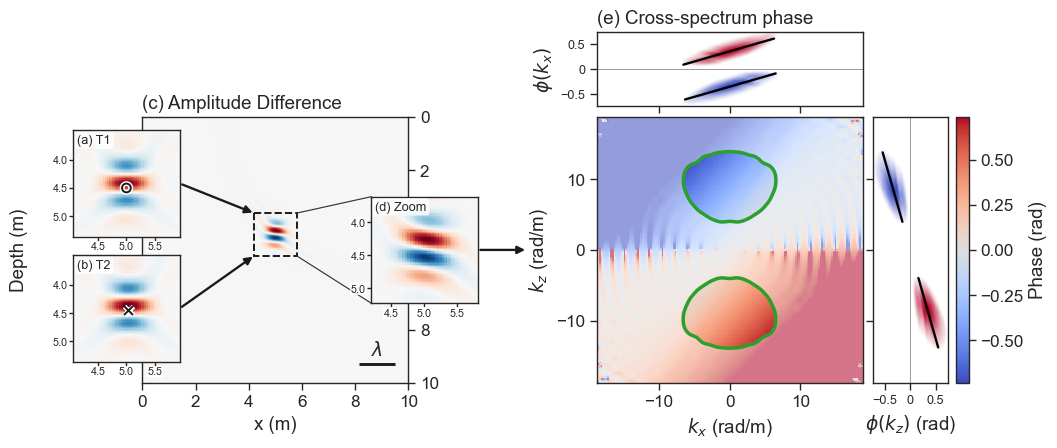

In [20]:
from matplotlib.patches import ConnectionPatch, Rectangle

# The method in one figure: the T1 (a) and T2 (b) migrated images around the scatterer, their
# amplitude difference over the whole model (c), a zoom on its dashed box (d), and the
# cross-spectrum phase with its density strips (e). Reuses the arrays and settings of the cells above.
T_HW_LAM = VIEW_HW_LAM * .7       # half-width of the view of (a), (b) [lambda]
BOX_HW_LAM = 0.6             # half-width of the dashed box = the view of (d) [lambda]
OVERVIEW_LIM = (0.0, 10.0)   # x and depth range of the overview (c) [m]
OVERVIEW_TICK = 2.0          # tick step of (c) [m]
ZOOM_TICK = 0.5              # tick step of the zoom panels (a), (b), (d) [m]
STRIP_TICKS = [-0.5, 0, 0.5]  # phase ticks of the strips of (e) [rad]

# Overview (c): the same Kirchhoff migration evaluated on its own grid over OVERVIEW_LIM, because
# the analysis grid X_IMG/Z_IMG stops at the survey ends. Migrating the difference of the tapered
# B-scans gives the difference of the images (the operator is linear).
X_OV = np.arange(OVERVIEW_LIM[0], OVERVIEW_LIM[1] + DX_IMG / 2, DX_IMG)
Z_OV = np.arange(OVERVIEW_LIM[0], OVERVIEW_LIM[1] + DZ_IMG / 2, DZ_IMG)
K_ov = Kirchhoff(Z_OV, X_OV, t, xz, xz, V, wav, n_w)
DIFF_OV = (K_ov.H @ (TAPERED['monitor'] - TAPERED['baseline']).T.ravel()).reshape(
    len(X_OV), len(Z_OV)).T
del K_ov

# Layout [inches / FIG_SCALE]: (c) and (e) are A x A squares, the zoom panels (a), (b), (d)
# SMALL x SMALL squares that overlap the left and right edges of (c). (b) sits high enough for
# its tick labels to clear those of (c), and (a) leaves room for its own tick labels below it.
A = 1.9
SMALL = 0.40 * A
OVERHANG = 0.26 * A                       # how far (a), (b) / (d) stick out of (c): keeps the
GAP_LABEL, GAP_ARROW = 0.5, 0.35          # edges of (c) off their centre tick labels
LEFT_PAD = 0.45                           # left of (a), (b): their tick labels + the depth label
x_c, y_c = LEFT_PAD + OVERHANG, 0.45      # lower-left corner of (c)
x_d = x_c + A + OVERHANG - SMALL
x_e = x_d + SMALL + GAP_ARROW + GAP_LABEL
W = x_e + (1.07 + MARG_FRAC + 0.05) * A + 0.6
H = y_c + (1.04 + MARG_FRAC) * A + 0.3


def add_ax(left, bottom, width, height):
    """Axes placed in inches / FIG_SCALE from the lower-left corner of the figure."""
    return fig.add_axes([left / W, bottom / H, width / W, height / H])


fig = plt.figure(figsize=(W * FIG_SCALE, H * FIG_SCALE))
ax_c = add_ax(x_c, y_c, A, A)                                   # drawn first: the rest on top
ax_a = add_ax(x_c - OVERHANG, y_c + 0.55 * A, SMALL, SMALL)
ax_b = add_ax(x_c - OVERHANG, y_c + 0.08 * A, SMALL, SMALL)
ax_d = add_ax(x_d, y_c + (A - SMALL) / 2, SMALL, SMALL)
ax_e = add_ax(x_e, y_c, A, A)

# (a)-(d) Migrated images, depth down; (a) and (b) share their axis limits
x0, z0 = X_IMG[ix0], Z_IMG[iz0]           # baseline scatterer = centre of the analysis window
t_hw, box_hw = T_HW_LAM * LAM, BOX_HW_LAM * LAM
T_VIEW = ((x0 - t_hw, x0 + t_hw), (z0 - t_hw, z0 + t_hw))
BOX = ((x0 - box_hw, x0 + box_hw), (z0 - box_hw, z0 + box_hw))
diff_img = IMG['monitor'] - IMG['baseline']
MARKER = {'baseline': dict(marker='o', mfc='none', mec='k'), 'monitor': dict(marker='x', mec='k')}


def image_view(ax, img, x_ax, z_ax, vmax, x_lim, z_lim, label=None, markers=(), tick=None):
    """Migrated image on the grid (x_ax, z_ax) with a symmetric colour scale, shown over x_lim,
    z_lim [m]; markers at the true scatterer positions, label upper left and small ticks every
    `tick` m (None: no ticks)."""
    ext = edge_extent(x_ax, z_ax)
    ax.imshow(img, extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper', cmap='RdBu_r',
              vmin=-vmax, vmax=vmax)
    for name in markers:
        ax.plot(*POS[name], **MARKER[name], **MK)
    ax.set_xlim(*x_lim)
    ax.set_ylim(z_lim[1], z_lim[0])
    if tick is None:
        ax.set_xticks([])
        ax.set_yticks([])
    else:                       # fixed ticks, labels on a white backing where they overlap (c)
        for set_ticks, lim in [(ax.set_xticks, x_lim), (ax.set_yticks, z_lim)]:
            pad = 0.05 * (lim[1] - lim[0])                # no tick right at a panel edge
            set_ticks(np.arange(np.ceil((lim[0] + pad) / tick),
                                np.floor((lim[1] - pad) / tick) + 1) * tick)
        ax.tick_params(labelsize=5.5 * FIG_SCALE, pad=1, length=2 * FIG_SCALE)
        for lbl in ax.get_xticklabels() + ax.get_yticklabels():
            lbl.set_bbox(dict(boxstyle='square,pad=0.1', fc='white', ec='none', alpha=0.8))
    if label:
        ax.text(0.04, 0.96, label, transform=ax.transAxes, ha='left', va='top', fontsize=fs,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8))


v_img, v_diff = np.abs(IMG['baseline']).max(), np.abs(diff_img).max()
image_view(ax_a, IMG['baseline'], X_IMG, Z_IMG, v_img, *T_VIEW, '(a) T1', ['baseline'], ZOOM_TICK)
image_view(ax_b, IMG['monitor'], X_IMG, Z_IMG, v_img, *T_VIEW, '(b) T2', ['monitor'], ZOOM_TICK)
image_view(ax_c, DIFF_OV, X_OV, Z_OV, v_diff, OVERVIEW_LIM, OVERVIEW_LIM)
image_view(ax_d, diff_img, X_IMG, Z_IMG, v_diff, *BOX, '(d) Zoom', tick=ZOOM_TICK)
ov_ticks = np.arange(OVERVIEW_LIM[0], OVERVIEW_LIM[1] + OVERVIEW_TICK / 2, OVERVIEW_TICK)
ax_c.set_xticks(ov_ticks)                 # full-size ticks; depth on the right, (d) hides 4, 6
ax_c.set_yticks(ov_ticks)
ax_c.yaxis.tick_right()
ax_c.set_xlabel('x (m)')
ax_c.set_ylabel('Depth (m)')
ax_c.yaxis.set_label_coords(-(OVERHANG + 0.17 * A) / A, 0.5)   # left of the tick labels of (a), (b)
ax_c.set_title('(c) Amplitude Difference', loc='left')

# Dashed box on the area of change, its zoom lines to (d) (drawn with (c), so the tick labels of
# (d) cover them), and a one-wavelength scale bar in (c)
ax_c.add_patch(Rectangle((BOX[0][0], BOX[1][0]), 2 * box_hw, 2 * box_hw, fill=False, ec='k',
                         ls='--', lw=FIG_SCALE))
for xy_box, xy_d in [((BOX[0][1], BOX[1][0]), (0, 1)), ((BOX[0][1], BOX[1][1]), (0, 0))]:
    ax_c.add_artist(ConnectionPatch(xy_box, xy_d, ax_c.transData, ax_d.transAxes,
                                    color='0.2', lw=0.6 * FIG_SCALE))
span = OVERVIEW_LIM[1] - OVERVIEW_LIM[0]
x_bar, z_bar = OVERVIEW_LIM[1] - 0.05 * span, OVERVIEW_LIM[1] - 0.07 * span   # bottom right
ax_c.plot([x_bar - LAM, x_bar], [z_bar, z_bar], color='k', lw=1.5 * FIG_SCALE,
          solid_capstyle='butt')
ax_c.text(x_bar - LAM / 2, z_bar - 0.02 * span, r'$\lambda$', ha='center', va='bottom',
          fontsize=plt.rcParams['axes.labelsize'])

# Arrows: (a), (b) -> dashed box, (d) -> (e)
arrow_kw = dict(arrowstyle='-|>', mutation_scale=8 * FIG_SCALE, lw=1.2 * FIG_SCALE, color='k',
                shrinkA=2, shrinkB=1)
fig.add_artist(ConnectionPatch((1, 0.5), (BOX[0][0], BOX[1][0]), ax_a.transAxes,
                               ax_c.transData, **arrow_kw))
fig.add_artist(ConnectionPatch((1, 0.5), (BOX[0][0], BOX[1][1]), ax_b.transAxes,
                               ax_c.transData, **arrow_kw))
fig.add_artist(ConnectionPatch((1, 0.5), ((x_e - GAP_LABEL) / W, (y_c + A / 2) / H),
                               ax_d.transAxes, 'figure fraction', **arrow_kw))

# (e) Cross-spectrum phase with the density strips, as in version A above but on wavenumber
# axes in rad/m
kx_r, kz_r, KX_r, KZ_r = (k * KZ_C for k in (kx_n, kz_n, KX_n, KZ_n))
im_e = ax_e.imshow(phase, extent=edge_extent(kx_r, kz_r), origin='lower', cmap=PHASE_CMAP,
                   vmin=-ph_lim, vmax=ph_lim, alpha=np.where(sel, 1.0, ALPHA_LOW))
ax_e.contour(kx_r, kz_r, amp, levels=[AMP_THR], colors='tab:green', linewidths=1.8 * FIG_SCALE)
ax_e.set_xlim(-K_LIM * KZ_C, K_LIM * KZ_C)
ax_e.set_ylim(-K_LIM * KZ_C, K_LIM * KZ_C)
ax_e.set_xlabel(r'$k_x$ (rad/m)')
ax_e.set_ylabel(r'$k_z$ (rad/m)')

ax_top = ax_e.inset_axes([0, 1.04, 1, MARG_FRAC], sharex=ax_e)
ax_rgt = ax_e.inset_axes([1.04, 0, MARG_FRAC, 1], sharey=ax_e)
for ax, k, k_ax, top in [(ax_top, KX_r, kx_r, True), (ax_rgt, KZ_r, kz_r, False)]:
    dens = strip_density(k, k_ax)
    d_max = max(dn.max() for dn in dens)     # full opacity at the strip's peak density
    for dn, cmap in zip(dens, lobe_cmaps):
        dn, ext_s = (dn, edge_extent(k_ax, ph_c)) if top else (dn.T, edge_extent(ph_c, k_ax))
        ax.imshow(dn, extent=ext_s, origin='lower', aspect='auto', interpolation='bilinear',
                  cmap=cmap, vmin=0, vmax=d_max)
for lobe in lobes:                           # fitted plane, one line per Hermitian lobe
    m_ = sel & lobe
    kz_mean, kx_mean = (np.average(k[m_], weights=amp[m_]) for k in (KZ_r, KX_r))
    kx_line = np.array([KX_r[m_].min(), KX_r[m_].max()])
    kz_line = np.array([KZ_r[m_].min(), KZ_r[m_].max()])
    ax_top.plot(kx_line, kx_line * dx_est + kz_mean * dz_est + phi0, **fit_kw)
    ax_rgt.plot(kz_line * dz_est + kx_mean * dx_est + phi0, kz_line, **fit_kw)
ax_top.axhline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
ax_rgt.axvline(0, color='0.5', lw=0.4 * FIG_SCALE, zorder=0)
strip_lbls = [f'{v:g}'.replace('-', '\N{MINUS SIGN}') for v in STRIP_TICKS]
ax_top.set_ylim(-ph_lim, ph_lim)
ax_top.set_yticks(STRIP_TICKS, strip_lbls, fontsize=fs)
ax_top.set_ylabel(r'$\phi(k_x)$')
ax_top.tick_params(labelbottom=False)
ax_rgt.set_xlim(-ph_lim, ph_lim)
ax_rgt.set_xticks(STRIP_TICKS, strip_lbls, fontsize=fs)
ax_rgt.set_xlabel(r'$\phi(k_z)$ (rad)')
ax_rgt.tick_params(labelleft=False)
ax_top.set_title('(e) Cross-spectrum phase', loc='left')
cb_e = fig.colorbar(im_e, cax=ax_e.inset_axes([1.07 + MARG_FRAC, 0, 0.05, 1]),
                    label='Phase (rad)')
cb_e.solids.set_alpha(1.0)                   # colour bar shows the opaque colours

fig.savefig(OUT_DIR / 'synthetic_movement_infographic.png', dpi=300, bbox_inches='tight')
plt.show()